# 逻辑回归

## 实验目标

实现一个二分类逻辑回归案例。
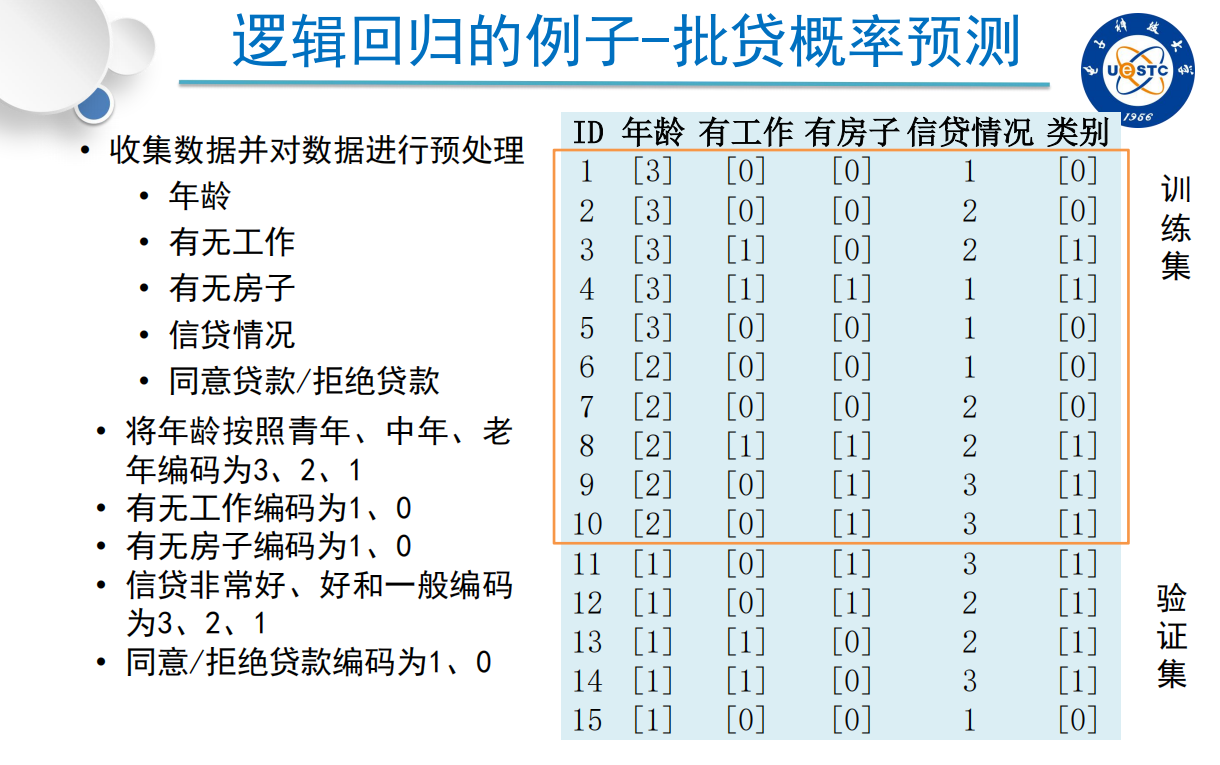

流程：
$$
\begin{aligned}
&w,b初始化（0或者随机） \\
\rightarrow &z=w^T x+b \\
\rightarrow &p=\sigma (z) \\
\rightarrow &BCE\; loss（Binary Cross Entropy 二元交叉熵） \\
\rightarrow &w,b更新
\end{aligned}
$$

## 实现步骤

### 准备工作

1. 导入numpy库

In [1]:
import numpy as np
import matplotlib.pyplot as plt

2. 初始化数据

In [2]:
# 训练集：ID 1~10
X_train = np.array(
    [
        [3, 0, 0, 1],
        [3, 0, 0, 2],
        [3, 1, 0, 2],
        [3, 1, 1, 1],
        [3, 0, 0, 1],
        [2, 0, 0, 1],
        [2, 0, 0, 2],
        [2, 1, 1, 2],
        [2, 0, 1, 3],
        [2, 0, 1, 3],
    ]
)

y_train = np.array([0, 0, 1, 1, 0, 0, 0, 1, 1, 1])

X_train, y_train

(array([[3, 0, 0, 1],
        [3, 0, 0, 2],
        [3, 1, 0, 2],
        [3, 1, 1, 1],
        [3, 0, 0, 1],
        [2, 0, 0, 1],
        [2, 0, 0, 2],
        [2, 1, 1, 2],
        [2, 0, 1, 3],
        [2, 0, 1, 3]]),
 array([0, 0, 1, 1, 0, 0, 0, 1, 1, 1]))

In [3]:
# 验证集：ID 11~15
X_val = np.array(
    [
        [1, 0, 1, 3],
        [1, 0, 1, 2],
        [1, 1, 0, 2],
        [1, 1, 0, 3],
        [1, 0, 0, 1],
    ]
)

y_val = np.array([1, 1, 1, 1, 0])

X_val, y_val

(array([[1, 0, 1, 3],
        [1, 0, 1, 2],
        [1, 1, 0, 2],
        [1, 1, 0, 3],
        [1, 0, 0, 1]]),
 array([1, 1, 1, 1, 0]))

### 模型函数

对一个$n$个特征的样本$x$，先通过线性模型得到线性分数$z=w^T x+b$，联系函数用sigmoid函数$p=\sigma(z)=\dfrac{1}{1+\mathrm{e}^{-z}}$.

其中$p$为预测为正类的概率。

sigmoid函数图像：
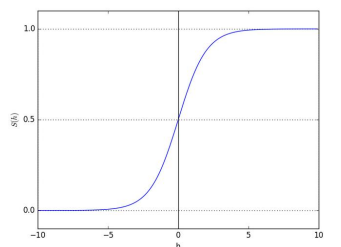

w, b初始化为0（也可随机），学习率为alpha

定义sigmoid函数

- 使用np.exp()而不是math.exp()，因为np库中的数学计算函数可以对numpy数组进行逐元素运算

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

定义训练函数
- 注意eps，可以防止可能产生的log(0)错误

In [5]:
def train(alpha, epochs):
    w = np.zeros(4)
    b = 0
    loss_history = []
    for epoch in range(epochs):
        # forward
        z = X_train @ w + b
        p = sigmoid(z)
    
        # loss
        eps = 1e-12 # 防止log(0)错误
        loss = np.mean(-(y_train * np.log(p + eps) + (1 - y_train) * np.log(1 - p + eps)))
    
        # gradient
        dw = X_train.T @ (p - y_train) / len(X_train)
        db = np.mean(p - y_train)
    
        # update
        w -= alpha * dw 
        b -= alpha * db
    
        # 记录每轮产生的loss
        loss_history.append(loss)
    return w, b, loss_history

开始训练

In [6]:
w1, b1, loss1 = train(1, 5000)
w2, b2, loss2 = train(0.1, 5000)
w3, b3, loss3 = train(0.01, 5000)
print(w1, b1)
print(w2, b2)
print(w3, b3)

[-2.42266787 12.69346481  8.91835899  2.2977508 ] -4.577517510295232
[-1.84857414  7.72880286  5.3464006   1.70686429] -2.454086732196919
[-1.13913883  3.17815286  2.64985039  1.04018998] -0.8068162452878321


画图观察loss的变化趋势：

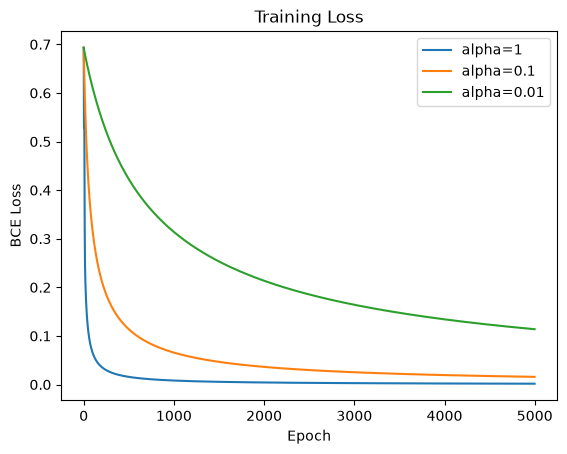

In [7]:
plt.plot(loss1, label="alpha=1")
plt.plot(loss2, label="alpha=0.1")
plt.plot(loss3, label="alpha=0.01")

plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Training Loss")

plt.legend()
plt.show()

验证集数据验证

In [8]:
z = X_val @ w1 + b1
res = (sigmoid(z) > 0.5).astype(int)
p_val = sigmoid(z)
accuracy = np.mean(res == y_val)

p_val, res, accuracy

(array([0.999851  , 0.99851918, 0.99996599, 0.99999658, 0.00899158]),
 array([1, 1, 1, 1, 0]),
 np.float64(1.0))

结果符合预期。

## 总结

二分类逻辑回归的步骤：
1. 模型：线性模型 $z=w^Tx+b$。
2. 策略：极大似然法，让似然函数最大化。对似然函数取负对数，既可简化计算又能将其转化为损失最小化。
3. 算法：梯度下降。其中:

   $$
   \begin{align}
   J&=\frac{1}{m}\sum_{i=1}^m L_i\\
   L_i&=-\left[ y_i\log p_i+\left(1-y_i\right) \log \left(1-p_i\right) \right] \\
   \frac{\partial L}{\partial p}&=\frac{1-y}{1-p}-\frac yp\\
   \frac{\partial p}{\partial z}&=\frac{\mathrm e^{-z}}{(1+\mathrm e^{-z})^2}\\
   &\to \\
   \frac{\partial L}{\partial w}&=(p-y)x,\frac{\partial L}{\partial b}=p-y
   \end{align}
   $$

   $m$个样本时便有$dw=\dfrac{1}{m}X^T(p-y),db=\dfrac{1}{m}\sum\limits_{i=1}^m(p_i-y_i)$

   梯度下降公式：
   $w \gets w-\alpha dw, b \gets b-\alpha db$

   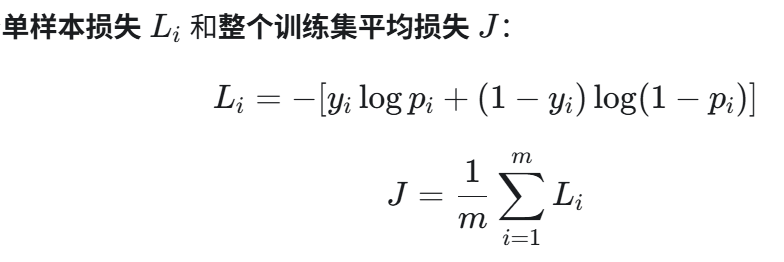